### 이진 분류 
note> 정답을 주고 학습하여 얼마나 틀린지 확인 : classification. <br> 정답없이 니가 알아서 하라 : clustering -> 인공지능의 방법
<br> 은닉층이 3차원 이상인 것 : deep learning 

In [4]:
import torch
import matplotlib.pyplot as plt 

##### Step 1. 데이터 생성 

In [13]:
N = 20

random0 = torch.randn(int(N/2),1)
random5 = torch.randn(int(N/2), 1)+5

# data
class1_data = torch.hstack([random0, random5]) # 10행 2열
class2_data = torch.hstack([random5, random0])

# label
class1_label = torch.ones(int(N/2), 1) # 10행 1열
class2_label = torch.zeros(int(N/2), 1)

x = torch.vstack([class1_data, class2_data]) # 20행 2열
y = torch.vstack([class1_label, class2_label]) # 20행 1열 
print(x)
print(y)

tensor([[-1.0061,  6.0564],
        [ 0.5748,  5.1133],
        [-0.6678,  5.0417],
        [-0.1172,  4.6726],
        [ 0.9283,  5.9872],
        [-0.9824,  4.9916],
        [-0.1826,  4.6590],
        [-1.1915,  3.5301],
        [-1.4425,  4.2224],
        [-1.3215,  4.2427],
        [ 6.0564, -1.0061],
        [ 5.1133,  0.5748],
        [ 5.0417, -0.6678],
        [ 4.6726, -0.1172],
        [ 5.9872,  0.9283],
        [ 4.9916, -0.9824],
        [ 4.6590, -0.1826],
        [ 3.5301, -1.1915],
        [ 4.2224, -1.4425],
        [ 4.2427, -1.3215]])
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.]])


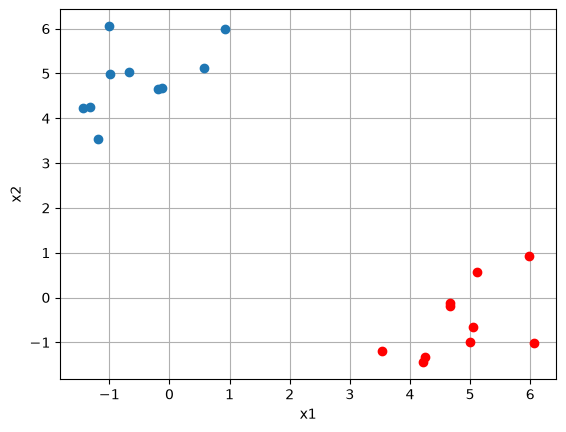

In [14]:
plt.plot(class1_data[:,0], class1_data[:,1],'o')
plt.plot(class2_data[:,0], class2_data[:,1],'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()

#### Step2. 모델 만들기

In [15]:
from torch import nn 

class MLP(nn.Module) : 
    def __init__(self) : 
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100), 
                                    nn.Sigmoid(),
                                    nn.Linear(100, 1),
                                    nn.Sigmoid()
                                    )
    def forward(self, x) : 
        x = self.linear(x)
        return x 

In [16]:
model = MLP()
# print(model)

b = model(torch.randn(5,2))
print(b.shape)
print(b)

torch.Size([5, 1])
tensor([[0.3965],
        [0.3981],
        [0.4024],
        [0.4037],
        [0.3919]], grad_fn=<SigmoidBackward0>)


#### Step 3. 모델 학습시키기

In [17]:
from torch import optim

LR = 1e-3
EPOCH = 1000

optimizer = optim.Adam(model.parameters(),lr = LR)
criterion = nn.BCELoss()

loss_history = []

model.train() # train mode로 전환 
for ep in range(EPOCH) : 
    # 예측값 
    y_hat = model(x)

    # loss 구하기 
    loss = criterion(y_hat, y)

    # update 
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # print
    loss_history += [loss.item()]
    print(f'Epoch : {ep+1}, train loss : {loss.item():.4f}')
    print('-'*20)

Epoch : 1, train loss : 0.6941
--------------------
Epoch : 2, train loss : 0.6806
--------------------
Epoch : 3, train loss : 0.6672
--------------------
Epoch : 4, train loss : 0.6542
--------------------
Epoch : 5, train loss : 0.6413
--------------------
Epoch : 6, train loss : 0.6287
--------------------
Epoch : 7, train loss : 0.6162
--------------------
Epoch : 8, train loss : 0.6041
--------------------
Epoch : 9, train loss : 0.5921
--------------------
Epoch : 10, train loss : 0.5804
--------------------
Epoch : 11, train loss : 0.5689
--------------------
Epoch : 12, train loss : 0.5577
--------------------
Epoch : 13, train loss : 0.5466
--------------------
Epoch : 14, train loss : 0.5358
--------------------
Epoch : 15, train loss : 0.5252
--------------------
Epoch : 16, train loss : 0.5149
--------------------
Epoch : 17, train loss : 0.5047
--------------------
Epoch : 18, train loss : 0.4948
--------------------
Epoch : 19, train loss : 0.4851
--------------------
Ep

Text(0, 0.5, 'Loss')

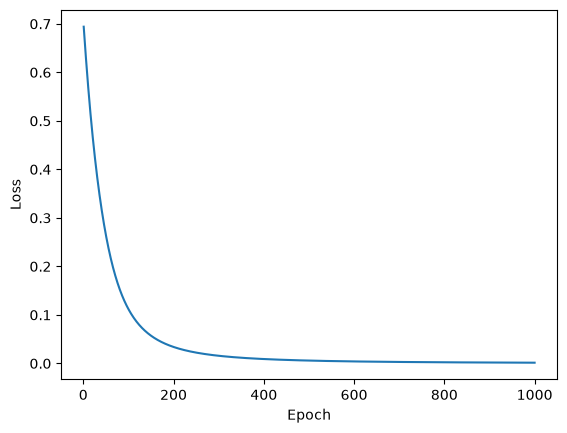

In [18]:
plt.plot(range(1,EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#### Step 4. 모델 테스트

tensor([-10.0000,  -9.3103,  -8.6207,  -7.9310,  -7.2414,  -6.5517,  -5.8621,
         -5.1724,  -4.4828,  -3.7931,  -3.1034,  -2.4138,  -1.7241,  -1.0345,
         -0.3448,   0.3448,   1.0345,   1.7241,   2.4138,   3.1034,   3.7931,
          4.4828,   5.1724,   5.8621,   6.5517,   7.2414,   7.9310,   8.6207,
          9.3103,  10.0000])


Text(0.5, 0.5, 'x2')

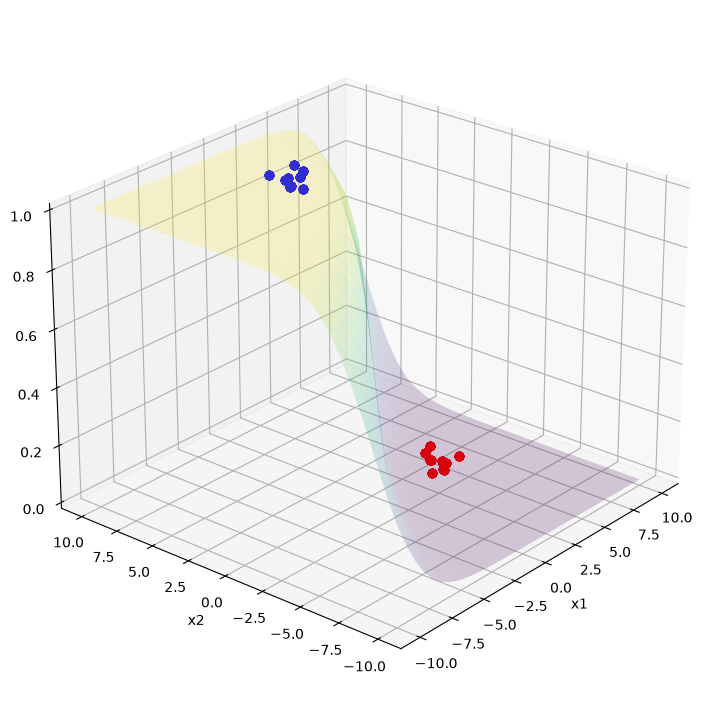

In [19]:
x1_test = torch.linspace(-10,10,30)  # x축 
x2_test = torch.linspace(-10,10,30)  # y축

X1_test, X2_test = torch.meshgrid(x1_test, x2_test) # (30,30)
print(x1_test)

X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2)
# (30, 30, 2)

model.eval()
with torch.no_grad():
    y_hat = model(X_test)  # 차원을 줄임 (30, 30, 1)

Y_hat = y_hat.squeeze()   # (30, 30)

plt.figure(figsize = (10, 9))
ax = plt.axes(projection = "3d")
ax.view_init(elev=25, azim=-140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='viridis', alpha = 0.2)
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('x2')